In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from skimage.metrics import (
    structural_similarity as ssim,
    peak_signal_noise_ratio as psnr
)

from torchvision import datasets, transforms
from torch.utils.data import DataLoader

import os
import time

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
print("PyTorch:", torch.__version__)

Device: cuda
PyTorch: 2.11.0+cu128


In [3]:
checkpoint_dir = "../results/checkpoints"
generated_dir = "../results/generated_images"

print("=== CHECKPOINT FILES ===")

if os.path.exists(checkpoint_dir):
    for file in os.listdir(checkpoint_dir):
        print(file)
else:
    print("Checkpoint directory not found!")

print("\n=== GENERATED IMAGE FILES ===")

if os.path.exists(generated_dir):
    for file in os.listdir(generated_dir):
        print(file)
else:
    print("Generated image directory not found!")

=== CHECKPOINT FILES ===
dcgan_discriminator.pth
dcgan_generator.pth
ddpm.pth
mlp_classifier.pth
mlp_experiment_data.pth
mlp_frozen_decoder.pth
sparse_autoencoder.pth
vae.pth
vanilla_autoencoder.pth
vanilla_gan_discriminator.pth
vanilla_gan_generator.pth

=== GENERATED IMAGE FILES ===
autoencoder_reconstruction.png
dcgan_generated.png
ddpm_generated.png
ddpm_trajectory.png
fid_samples
mlp_frozen_decoder.png
mlp_latent_transpose.png
mlp_random_prior.png
mlp_weight_transpose.png
vae_generated.png
vanilla_gan_generated.png


In [4]:
import torch
import torch.nn as nn

class VanillaAutoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 64)
        )
        self.decoder = nn.Sequential(
            nn.Linear(64, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = x.view(x.size(0), -1)
        return self.decoder(self.encoder(x))


class SparseAutoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 64),
            nn.ReLU()
        )
        self.decoder = nn.Sequential(
            nn.Linear(64, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = x.view(x.size(0), -1)
        return self.decoder(self.encoder(x))


class VariationalAutoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(784, 256),
            nn.ReLU()
        )
        self.fc_mu = nn.Linear(256, 64)
        self.fc_logvar = nn.Linear(256, 64)

        self.decoder = nn.Sequential(
            nn.Linear(64, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def forward(self, x):
        x = x.view(x.size(0), -1)
        hidden = self.encoder(x)

        mu = self.fc_mu(hidden)
        logvar = self.fc_logvar(hidden)

        z = self.reparameterize(mu, logvar)
        reconstructed = self.decoder(z)

        return reconstructed, mu, logvar

In [5]:
vanilla_ae = VanillaAutoencoder().to(device)
sparse_ae = SparseAutoencoder().to(device)
vae = VariationalAutoencoder().to(device)

vanilla_ae.load_state_dict(
    torch.load("../results/checkpoints/vanilla_autoencoder.pth",
               map_location=device, weights_only=True)
)

sparse_ae.load_state_dict(
    torch.load("../results/checkpoints/sparse_autoencoder.pth",
               map_location=device, weights_only=True)
)

vae.load_state_dict(
    torch.load("../results/checkpoints/vae.pth",
               map_location=device, weights_only=True)
)

vanilla_ae.eval()
sparse_ae.eval()
vae.eval()

print("All three autoencoder models loaded successfully!")

All three autoencoder models loaded successfully!


In [6]:
print("Dataset variables:")

for name in ["train_dataset", "val_dataset", "test_dataset"]:
    if name in globals():
        print(f"{name}: {len(globals()[name])} images")

print("\nDataLoader variables:")

for name in ["train_loader", "val_loader", "test_loader"]:
    if name in globals():
        print(f"{name}: {len(globals()[name])} batches")

Dataset variables:

DataLoader variables:


In [7]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split, ConcatDataset

# Transform
transform = transforms.ToTensor()

# Load Fashion-MNIST
train_raw = datasets.FashionMNIST(
    root="../data",
    train=True,
    download=True,
    transform=transform
)

test_raw = datasets.FashionMNIST(
    root="../data",
    train=False,
    download=True,
    transform=transform
)

# Combine datasets
full_dataset = ConcatDataset([train_raw, test_raw])

# Original split configuration
total_size = len(full_dataset)

train_size = int(0.8 * total_size)
val_size = int(0.1 * total_size)
test_size = total_size - train_size - val_size

# Fixed seed
generator = torch.Generator().manual_seed(42)

train_dataset, val_dataset, test_dataset = random_split(
    full_dataset,
    [train_size, val_size, test_size],
    generator=generator
)

# DataLoader
BATCH_SIZE = 128

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Total dataset:", total_size)
print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Testing:", len(test_dataset))
print("Testing batches:", len(test_loader))

Total dataset: 70000
Training: 56000
Validation: 7000
Testing: 7000
Testing batches: 55


In [8]:
import numpy as np
from skimage.metrics import structural_similarity as ssim

def evaluate_autoencoder(model, test_loader, model_type="ae"):
    model.eval()

    mse_scores = []
    psnr_scores = []
    ssim_scores = []

    with torch.no_grad():
        for images, _ in test_loader:
            images = images.to(device)
            original = images.view(images.size(0), -1)

            if model_type == "vae":
                hidden = model.encoder(original)
                mu = model.fc_mu(hidden)
                reconstructed = model.decoder(mu)
            else:
                reconstructed = model(original)

            reconstructed = reconstructed.view(-1, 1, 28, 28)
            original = images.view(-1, 1, 28, 28)

            for i in range(images.size(0)):
                orig = original[i, 0].cpu().numpy()
                recon = reconstructed[i, 0].cpu().numpy()

                mse = np.mean((orig - recon) ** 2)
                psnr = 10 * np.log10(1.0 / max(mse, 1e-10))
                ssim_value = ssim(orig, recon, data_range=1.0)

                mse_scores.append(mse)
                psnr_scores.append(psnr)
                ssim_scores.append(ssim_value)

    return {
        "MSE": np.mean(mse_scores),
        "PSNR": np.mean(psnr_scores),
        "SSIM": np.mean(ssim_scores)
    }

In [9]:
results = {}

results["Vanilla AE"] = evaluate_autoencoder(
    vanilla_ae, test_loader
)

results["Sparse AE"] = evaluate_autoencoder(
    sparse_ae, test_loader
)

results["VAE"] = evaluate_autoencoder(
    vae, test_loader, model_type="vae"
)

for model_name, metrics in results.items():
    print(f"\n{model_name}")
    for metric, value in metrics.items():
        print(f"{metric}: {value:.6f}")


Vanilla AE
MSE: 0.006567
PSNR: 22.958798
SSIM: 0.827014

Sparse AE
MSE: 0.007825
PSNR: 22.124467
SSIM: 0.798745

VAE
MSE: 0.017325
PSNR: 18.295819
SSIM: 0.640262


In [10]:
os.makedirs("../results/metrics", exist_ok=True)

results_df = pd.DataFrame(results).T
results_df.index.name = "Model"

results_df.to_csv(
    "../results/metrics/autoencoder_metrics.csv"
)

display(results_df)

print("Autoencoder metrics saved successfully!")

,MSE,PSNR,SSIM
Model,,,
Vanilla AE,0.006567,22.958798,0.827014
Sparse AE,0.007825,22.124467,0.798745
VAE,0.017325,18.295819,0.640262


Autoencoder metrics saved successfully!


In [11]:
import matplotlib.pyplot as plt

# Ambil satu batch dari test set
images, labels = next(iter(test_loader))
images = images[:8].to(device)

# Generate reconstruction
with torch.no_grad():
    original = images.view(images.size(0), -1)

    vanilla_recon = vanilla_ae(original)
    sparse_recon = sparse_ae(original)

    hidden = vae.encoder(original)
    mu = vae.fc_mu(hidden)
    vae_recon = vae.decoder(mu)

# Convert to image format
original = original.view(-1, 1, 28, 28).cpu()
vanilla_recon = vanilla_recon.view(-1, 1, 28, 28).cpu()
sparse_recon = sparse_recon.view(-1, 1, 28, 28).cpu()
vae_recon = vae_recon.view(-1, 1, 28, 28).cpu()

# Plot
fig, axes = plt.subplots(4, 8, figsize=(14, 7))

titles = ["Original", "Vanilla AE", "Sparse AE", "VAE"]
data = [original, vanilla_recon, sparse_recon, vae_recon]

for row in range(4):
    for col in range(8):
        axes[row, col].imshow(data[row][col][0], cmap="gray")
        axes[row, col].axis("off")

        if col == 0:
            axes[row, col].set_ylabel(
                titles[row], fontsize=11
            )

plt.suptitle("Autoencoder Reconstruction Comparison")
plt.tight_layout()

os.makedirs("../results/generated_images", exist_ok=True)

plt.savefig(
    "../results/generated_images/autoencoder_reconstruction.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

<Figure size 1400x700 with 32 Axes>

In [12]:
class Generator(nn.Module):
    def __init__(self, latent_dim=100):
        super().__init__()

        self.model = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 512),
            nn.ReLU(),
            nn.Linear(512, 784),
            nn.Sigmoid()
        )

    def forward(self, z):
        return self.model(z)


class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()

        self.model = nn.Sequential(
            nn.Linear(784, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 1)
        )

    def forward(self, x):
        return self.model(x)

In [13]:
latent_dim = 100

gan_generator = Generator(latent_dim).to(device)
gan_discriminator = Discriminator().to(device)

gan_generator.load_state_dict(
    torch.load(
        "../results/checkpoints/vanilla_gan_generator.pth",
        map_location=device,
        weights_only=True
    )
)

gan_discriminator.load_state_dict(
    torch.load(
        "../results/checkpoints/vanilla_gan_discriminator.pth",
        map_location=device,
        weights_only=True
    )
)

gan_generator.eval()
gan_discriminator.eval()

print("Vanilla GAN loaded successfully!")

Vanilla GAN loaded successfully!


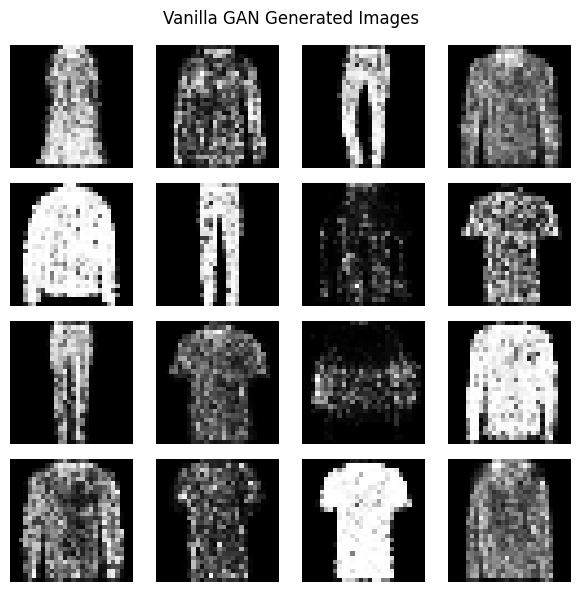

In [14]:
with torch.no_grad():
    z = torch.randn(16, latent_dim, device=device)
    generated = gan_generator(z)

generated = generated.view(-1, 1, 28, 28).cpu()

fig, axes = plt.subplots(4, 4, figsize=(6, 6))

for i, ax in enumerate(axes.flat):
    ax.imshow(generated[i, 0], cmap="gray")
    ax.axis("off")

plt.suptitle("Vanilla GAN Generated Images")
plt.tight_layout()
plt.show()

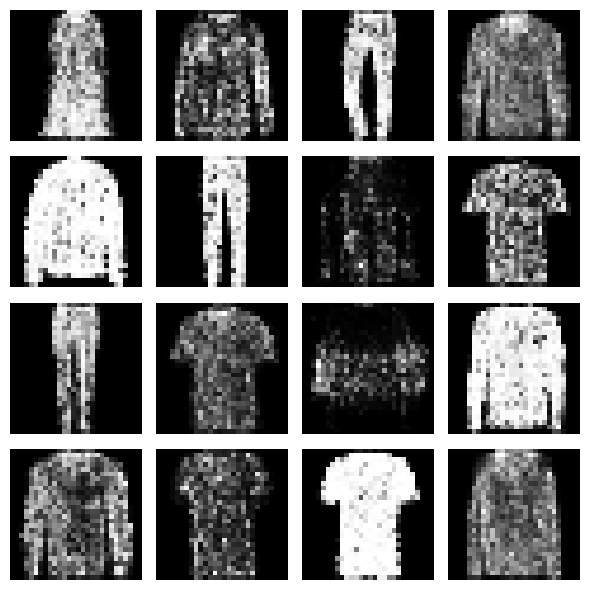

In [15]:
os.makedirs("../results/generated_images", exist_ok=True)

plt.figure(figsize=(6, 6))

for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.imshow(generated[i, 0], cmap="gray")
    plt.axis("off")

plt.tight_layout()

plt.savefig(
    "../results/generated_images/vanilla_gan_generated.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [16]:
class DCGANGenerator(nn.Module):
    def __init__(self, latent_dim=100):
        super().__init__()

        self.model = nn.Sequential(
            nn.ConvTranspose2d(
                latent_dim, 128, 7, 1, 0, bias=False
            ),
            nn.BatchNorm2d(128),
            nn.ReLU(True),

            nn.ConvTranspose2d(
                128, 64, 4, 2, 1, bias=False
            ),
            nn.BatchNorm2d(64),
            nn.ReLU(True),

            nn.ConvTranspose2d(
                64, 1, 4, 2, 1
            ),
            nn.Tanh()
        )

    def forward(self, z):
        return self.model(z)


class DCGANDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()

        self.model = nn.Sequential(
            nn.Conv2d(1, 64, 4, 2, 1),
            nn.LeakyReLU(0.2, True),

            nn.Conv2d(64, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, True),

            nn.Flatten(),
            nn.Linear(6272, 1)
        )

    def forward(self, x):
        return self.model(x)

In [17]:
dcgan_generator = DCGANGenerator(100).to(device)
dcgan_discriminator = DCGANDiscriminator().to(device)

dcgan_generator.load_state_dict(
    torch.load(
        "../results/checkpoints/dcgan_generator.pth",
        map_location=device,
        weights_only=True
    )
)

dcgan_discriminator.load_state_dict(
    torch.load(
        "../results/checkpoints/dcgan_discriminator.pth",
        map_location=device,
        weights_only=True
    )
)

dcgan_generator.eval()
dcgan_discriminator.eval()

print("DCGAN loaded successfully!")

DCGAN loaded successfully!


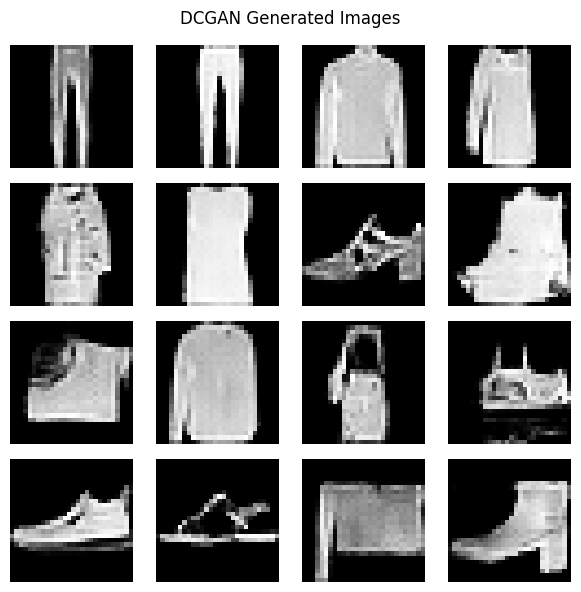

In [18]:
with torch.no_grad():
    z = torch.randn(16, 100, 1, 1, device=device)
    dcgan_generated = dcgan_generator(z)

# Convert output from [-1, 1] to [0, 1]
dcgan_generated = (
    dcgan_generated.clamp(-1, 1) + 1
) / 2

dcgan_generated = dcgan_generated.cpu()

fig, axes = plt.subplots(4, 4, figsize=(6, 6))

for i, ax in enumerate(axes.flat):
    ax.imshow(dcgan_generated[i, 0], cmap="gray")
    ax.axis("off")

plt.suptitle("DCGAN Generated Images")
plt.tight_layout()
plt.show()

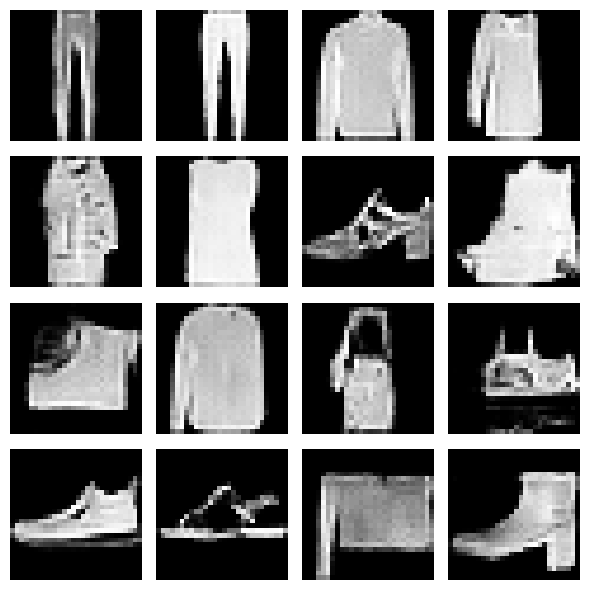

In [19]:
os.makedirs("../results/generated_images", exist_ok=True)

fig, axes = plt.subplots(4, 4, figsize=(6, 6))

for i, ax in enumerate(axes.flat):
    ax.imshow(dcgan_generated[i, 0], cmap="gray")
    ax.axis("off")

plt.tight_layout()

plt.savefig(
    "../results/generated_images/dcgan_generated.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [20]:
import torch.nn.functional as F
import math

class DDPMNetwork(nn.Module):
    def __init__(self, time_dim=128):
        super().__init__()

        self.time_mlp = nn.Sequential(
            nn.Linear(time_dim, time_dim),
            nn.ReLU()
        )

        self.conv1 = nn.Conv2d(1, 64, 3, 1, 1)
        self.conv2 = nn.Conv2d(64, 128, 4, 2, 1)
        self.bottleneck = nn.Conv2d(128, 128, 3, 1, 1)
        self.up = nn.ConvTranspose2d(128, 64, 4, 2, 1)
        self.output = nn.Conv2d(128, 1, 3, 1, 1)

        self.time_projection = nn.Linear(time_dim, 128)

    def forward(self, x, t):
        # Sinusoidal time embedding
        half_dim = 64
        emb_scale = math.log(10000) / (half_dim - 1)

        emb = torch.exp(
            torch.arange(
                half_dim, device=x.device
            ) * -emb_scale
        )

        emb = t.float().unsqueeze(1) * emb.unsqueeze(0)

        emb = torch.cat(
            [torch.sin(emb), torch.cos(emb)],
            dim=1
        )

        time_emb = self.time_mlp(emb)
        time_emb = self.time_projection(time_emb)

        # Encoder
        h1 = F.relu(self.conv1(x))
        h2 = F.relu(self.conv2(h1))

        # Bottleneck + time embedding
        h = self.bottleneck(h2)
        h = F.relu(h + time_emb[:, :, None, None])

        # Decoder + skip connection
        h = self.up(h)
        h = torch.cat([h, h1], dim=1)

        return self.output(h)

In [21]:
ddpm_model = DDPMNetwork().to(device)

ddpm_model.load_state_dict(
    torch.load(
        "../results/checkpoints/ddpm.pth",
        map_location=device,
        weights_only=True
    )
)

ddpm_model.eval()

print("DDPM loaded successfully!")

DDPM loaded successfully!


DDPM generated image exists: True
DDPM trajectory exists: True


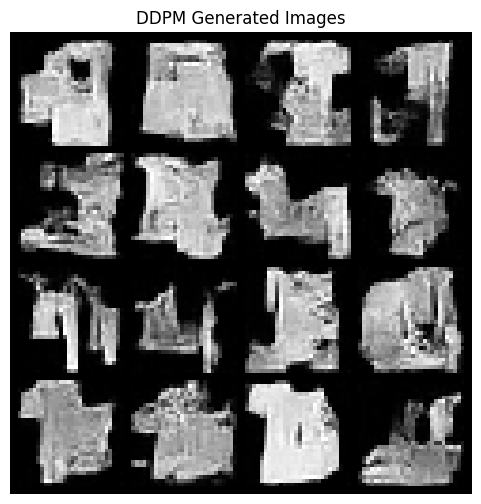

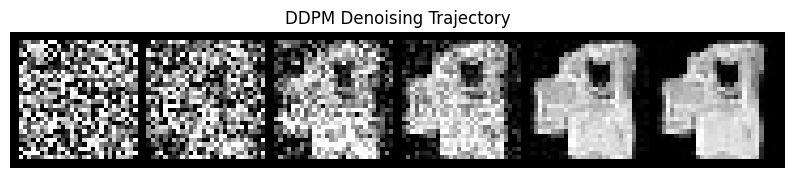

In [22]:
from PIL import Image
import os
import matplotlib.pyplot as plt

ddpm_image_path = "../results/generated_images/ddpm_generated.png"
trajectory_path = "../results/generated_images/ddpm_trajectory.png"

print("DDPM generated image exists:", os.path.exists(ddpm_image_path))
print("DDPM trajectory exists:", os.path.exists(trajectory_path))

# Display generated images
img = Image.open(ddpm_image_path)
plt.figure(figsize=(6, 6))
plt.imshow(img)
plt.title("DDPM Generated Images")
plt.axis("off")
plt.show()

# Display denoising trajectory
img = Image.open(trajectory_path)
plt.figure(figsize=(10, 5))
plt.imshow(img)
plt.title("DDPM Denoising Trajectory")
plt.axis("off")
plt.show()

In [23]:
import importlib.util

packages = [
    "torchmetrics",
    "torch_fidelity",
    "torchvision"
]

for package in packages:
    installed = importlib.util.find_spec(package) is not None
    print(f"{package}: {'Installed' if installed else 'Not installed'}")

torchmetrics: Installed
torch_fidelity: Installed
torchvision: Installed


In [24]:
%pip install torchmetrics torch-fidelity

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [25]:
import torch
import torchmetrics
import torch_fidelity

print("PyTorch:", torch.__version__)
print("TorchMetrics:", torchmetrics.__version__)
print("Torch Fidelity:", torch_fidelity.__version__)
print("CUDA available:", torch.cuda.is_available())

d:\PYTHON\environment\Deep Learning\environments\deep_learning\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch: 2.11.0+cu128
TorchMetrics: 1.9.0
Torch Fidelity: 0.4.0
CUDA available: True


In [26]:
# FID configuration

FID_SAMPLES = 2000
FID_BATCH_SIZE = 64

print("FID samples per model:", FID_SAMPLES)
print("FID batch size:", FID_BATCH_SIZE)
print("Device:", device)

FID samples per model: 2000
FID batch size: 64
Device: cuda


In [27]:
print("DDPM checkpoint:",
      os.path.exists("../results/checkpoints/ddpm.pth"))

print("DDPM generated images:",
      os.path.exists("../results/generated_images/ddpm_generated.png"))

print("DDPM trajectory:",
      os.path.exists("../results/generated_images/ddpm_trajectory.png"))

DDPM checkpoint: True
DDPM generated images: True
DDPM trajectory: True


In [28]:
def sinusoidal_embedding(t, dim):
    half_dim = dim // 2

    embeddings = math.log(10000) / (half_dim - 1)

    embeddings = torch.exp(
        torch.arange(half_dim, device=t.device) * -embeddings
    )

    embeddings = t[:, None] * embeddings[None, :]

    embeddings = torch.cat(
        [torch.sin(embeddings), torch.cos(embeddings)],
        dim=-1
    )

    return embeddings


class DDPMNetwork(nn.Module):
    def __init__(self, time_dim=128):
        super().__init__()

        self.time_dim = time_dim

        self.time_mlp = nn.Sequential(
            nn.Linear(time_dim, time_dim),
            nn.ReLU()
        )

        self.conv1 = nn.Conv2d(1, 64, 3, 1, 1)
        self.conv2 = nn.Conv2d(64, 128, 4, 2, 1)
        self.bottleneck = nn.Conv2d(128, 128, 3, 1, 1)
        self.up = nn.ConvTranspose2d(128, 64, 4, 2, 1)
        self.output = nn.Conv2d(128, 1, 3, 1, 1)

        self.time_projection = nn.Linear(time_dim, 128)

    def forward(self, x, t):
        time_embedding = sinusoidal_embedding(t, self.time_dim)
        time_embedding = self.time_mlp(time_embedding)
        time_embedding = self.time_projection(time_embedding)

        x1 = F.relu(self.conv1(x))
        x2 = F.relu(self.conv2(x1))

        time_embedding = time_embedding[:, :, None, None]

        x2 = x2 + time_embedding
        x2 = F.relu(self.bottleneck(x2))

        x3 = F.relu(self.up(x2))
        x3 = torch.cat([x3, x1], dim=1)

        return self.output(x3)

In [29]:
TIMESTEPS = 300
CHANNELS = 1
IMAGE_SIZE = 28

beta_start = 1e-4
beta_end = 0.02

betas = torch.linspace(
    beta_start, beta_end, TIMESTEPS
).to(device)

alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)

ddpm_model = DDPMNetwork(time_dim=128).to(device)

ddpm_model.load_state_dict(
    torch.load(
        "../results/checkpoints/ddpm.pth",
        map_location=device,
        weights_only=True
    )
)

ddpm_model.eval()

print("DDPM checkpoint loaded successfully!")
print("Timesteps:", TIMESTEPS)
print("Beta range:", betas[0].item(), "to", betas[-1].item())

DDPM checkpoint loaded successfully!
Timesteps: 300
Beta range: 9.999999747378752e-05 to 0.019999999552965164


In [30]:
@torch.no_grad()
def generate_ddpm_batch(model, num_samples=64):

    model.eval()

    x = torch.randn(
        num_samples, CHANNELS, IMAGE_SIZE, IMAGE_SIZE,
        device=device
    )

    for t in reversed(range(TIMESTEPS)):

        t_batch = torch.full(
            (num_samples,),
            t,
            device=device,
            dtype=torch.long
        )

        predicted_noise = model(x, t_batch)

        alpha = alphas[t]
        alpha_bar = alpha_bars[t]
        beta = betas[t]

        noise = (
            torch.randn_like(x)
            if t > 0 else torch.zeros_like(x)
        )

        x = (1 / torch.sqrt(alpha)) * (
            x - (beta / torch.sqrt(1 - alpha_bar))
            * predicted_noise
        ) + torch.sqrt(beta) * noise

    # Convert [-1, 1] to [0, 1]
    return ((x.clamp(-1, 1) + 1) / 2)


ddpm_samples = []

for i in range(0, 2000, FID_BATCH_SIZE):
    batch = generate_ddpm_batch(
        ddpm_model,
        num_samples=min(FID_BATCH_SIZE, 2000 - i)
    )

    ddpm_samples.append(batch.cpu())

ddpm_samples = torch.cat(ddpm_samples, dim=0)

os.makedirs("../results/generated_images/fid_samples", exist_ok=True)

torch.save(
    ddpm_samples,
    "../results/generated_images/fid_samples/ddpm_samples.pt"
)

print("DDPM samples:", ddpm_samples.shape)

DDPM samples: torch.Size([2000, 1, 28, 28])


In [31]:
os.makedirs(
    "../results/generated_images/fid_samples",
    exist_ok=True
)

# 1. VAE
vae_samples = []

with torch.no_grad():
    for i in range(0, FID_SAMPLES, FID_BATCH_SIZE):
        batch_size = min(FID_BATCH_SIZE, FID_SAMPLES - i)

        z = torch.randn(batch_size, 64, device=device)
        generated = vae.decoder(z)

        vae_samples.append(
            generated.view(-1, 1, 28, 28).cpu()
        )

vae_samples = torch.cat(vae_samples)

# 2. Vanilla GAN
gan_samples = []

with torch.no_grad():
    for i in range(0, FID_SAMPLES, FID_BATCH_SIZE):
        batch_size = min(FID_BATCH_SIZE, FID_SAMPLES - i)

        z = torch.randn(batch_size, 100, device=device)
        generated = gan_generator(z)

        gan_samples.append(
            generated.view(-1, 1, 28, 28).cpu()
        )

gan_samples = torch.cat(gan_samples)

# 3. DCGAN
dcgan_samples = []

with torch.no_grad():
    for i in range(0, FID_SAMPLES, FID_BATCH_SIZE):
        batch_size = min(FID_BATCH_SIZE, FID_SAMPLES - i)

        z = torch.randn(batch_size, 100, 1, 1, device=device)
        generated = dcgan_generator(z)

        generated = (generated.clamp(-1, 1) + 1) / 2

        dcgan_samples.append(generated.cpu())

dcgan_samples = torch.cat(dcgan_samples)

# Save all samples
torch.save(
    vae_samples,
    "../results/generated_images/fid_samples/vae_samples.pt"
)

torch.save(
    gan_samples,
    "../results/generated_images/fid_samples/vanilla_gan_samples.pt"
)

torch.save(
    dcgan_samples,
    "../results/generated_images/fid_samples/dcgan_samples.pt"
)

print("VAE:", vae_samples.shape)
print("Vanilla GAN:", gan_samples.shape)
print("DCGAN:", dcgan_samples.shape)
print("All generated samples saved!")

VAE: torch.Size([2000, 1, 28, 28])
Vanilla GAN: torch.Size([2000, 1, 28, 28])
DCGAN: torch.Size([2000, 1, 28, 28])
All generated samples saved!


In [32]:
from torch.utils.data import Subset, DataLoader

# Select 2000 test images with fixed seed
generator = torch.Generator().manual_seed(42)

indices = torch.randperm(
    len(test_dataset),
    generator=generator
)[:FID_SAMPLES].tolist()

real_subset = Subset(test_dataset, indices)

real_loader = DataLoader(
    real_subset,
    batch_size=FID_BATCH_SIZE,
    shuffle=False
)

# Collect real images
real_samples = []

for images, _ in real_loader:
    real_samples.append(images)

real_samples = torch.cat(real_samples, dim=0)

# Save real samples
torch.save(
    real_samples,
    "../results/generated_images/fid_samples/real_samples.pt"
)

print("Real samples:", real_samples.shape)
print("Value range:", real_samples.min().item(),
      "to", real_samples.max().item())

Real samples: torch.Size([2000, 1, 28, 28])
Value range: 0.0 to 1.0


In [33]:
from torchmetrics.image.fid import FrechetInceptionDistance

fid = FrechetInceptionDistance(
    feature=64,
    normalize=False
).to(device)

print("FID calculator initialized!")

FID calculator initialized!


In [34]:
def prepare_fid_batch(images):
    # Convert grayscale to RGB
    images = images.repeat(1, 3, 1, 1)

    # Resize only current batch
    images = F.interpolate(
        images,
        size=(299, 299),
        mode="bilinear",
        align_corners=False
    )

    # Convert to uint8
    images = (images.clamp(0, 1) * 255).to(torch.uint8)

    return images

In [35]:
def calculate_fid(real_samples, generated_samples):

    fid = FrechetInceptionDistance(
        feature=64,
        normalize=False
    ).to(device)

    # Process real images in batches
    for i in range(0, len(real_samples), FID_BATCH_SIZE):
        batch = real_samples[i:i + FID_BATCH_SIZE]

        batch = prepare_fid_batch(batch).to(device)
        fid.update(batch, real=True)

        del batch

    # Process generated images in batches
    for i in range(0, len(generated_samples), FID_BATCH_SIZE):
        batch = generated_samples[i:i + FID_BATCH_SIZE]

        batch = prepare_fid_batch(batch).to(device)
        fid.update(batch, real=False)

        del batch

    score = fid.compute().item()

    del fid
    torch.cuda.empty_cache()

    return score

In [36]:
fid_results = {}

models_samples = {
    "VAE": vae_samples,
    "Vanilla GAN": gan_samples,
    "DCGAN": dcgan_samples,
    "DDPM": ddpm_samples
}

for name, samples in models_samples.items():

    print(f"\nCalculating FID: {name}")

    score = calculate_fid(
        real_samples,
        samples
    )

    fid_results[name] = score

    print(f"FID: {score:.4f}")

print("\nFID evaluation completed!")


Calculating FID: VAE
FID: 0.3437

Calculating FID: Vanilla GAN
FID: 0.4309

Calculating FID: DCGAN
FID: 0.0105

Calculating FID: DDPM
FID: 0.8970

FID evaluation completed!


In [37]:
fid_df = pd.DataFrame(
    list(fid_results.items()),
    columns=["Model", "FID"]
)

fid_df = fid_df.sort_values("FID")

fid_df.to_csv(
    "../results/metrics/fid_comparison.csv",
    index=False
)

display(fid_df)

print("FID results saved successfully!")

,Model,FID
2,DCGAN,0.010504
0,VAE,0.343673
1,Vanilla GAN,0.430921
3,DDPM,0.897034


FID results saved successfully!


In [38]:
LATENCY_BATCH = 64
WARMUP = 5
REPEATS = 30

def benchmark_latency(func):

    # Warm-up
    with torch.no_grad():
        for _ in range(WARMUP):
            func()

    if device.type == "cuda":
        torch.cuda.synchronize()

    start = time.perf_counter()

    with torch.no_grad():
        for _ in range(REPEATS):
            func()

    if device.type == "cuda":
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start

    return (elapsed / REPEATS) * 1000


# Prepare fixed inputs
x = torch.rand(LATENCY_BATCH, 1, 28, 28, device=device)

z_gan = torch.randn(LATENCY_BATCH, 100, device=device)
z_dcgan = torch.randn(LATENCY_BATCH, 100, 1, 1, device=device)

def run_vae():
    hidden = vae.encoder(x.view(LATENCY_BATCH, -1))
    mu = vae.fc_mu(hidden)
    return vae.decoder(mu)

def run_ddpm():
    return generate_ddpm_batch(
        ddpm_model,
        num_samples=LATENCY_BATCH
    )


latency_results = {
    "Vanilla AE": benchmark_latency(
        lambda: vanilla_ae(x)
    ),
    "Sparse AE": benchmark_latency(
        lambda: sparse_ae(x)
    ),
    "VAE": benchmark_latency(run_vae),
    "Vanilla GAN": benchmark_latency(
        lambda: gan_generator(z_gan)
    ),
    "DCGAN": benchmark_latency(
        lambda: dcgan_generator(z_dcgan)
    ),
    "DDPM": benchmark_latency(run_ddpm)
}

latency_df = pd.DataFrame(
    list(latency_results.items()),
    columns=["Model", "Latency (ms/batch)"]
)

display(latency_df)

,Model,Latency (ms/batch)
0,Vanilla AE,0.503617
1,Sparse AE,0.464207
2,VAE,0.432393
3,Vanilla GAN,0.220013
4,DCGAN,2.229007
5,DDPM,942.372670


In [39]:
latency_df.to_csv(
    "../results/metrics/inference_latency.csv",
    index=False
)

print("Inference latency saved successfully!")

Inference latency saved successfully!


In [41]:
history_names = [
    "train_losses",
    "val_losses",
    "train_loss_history",
    "val_loss_history",
    "G_losses",
    "D_losses",
    "generator_losses",
    "discriminator_losses",
    "ddpm_losses",
    "train_loss",
    "val_loss"
]

for name in history_names:
    if name in globals():
        print(name, ":", type(globals()[name]).__name__)

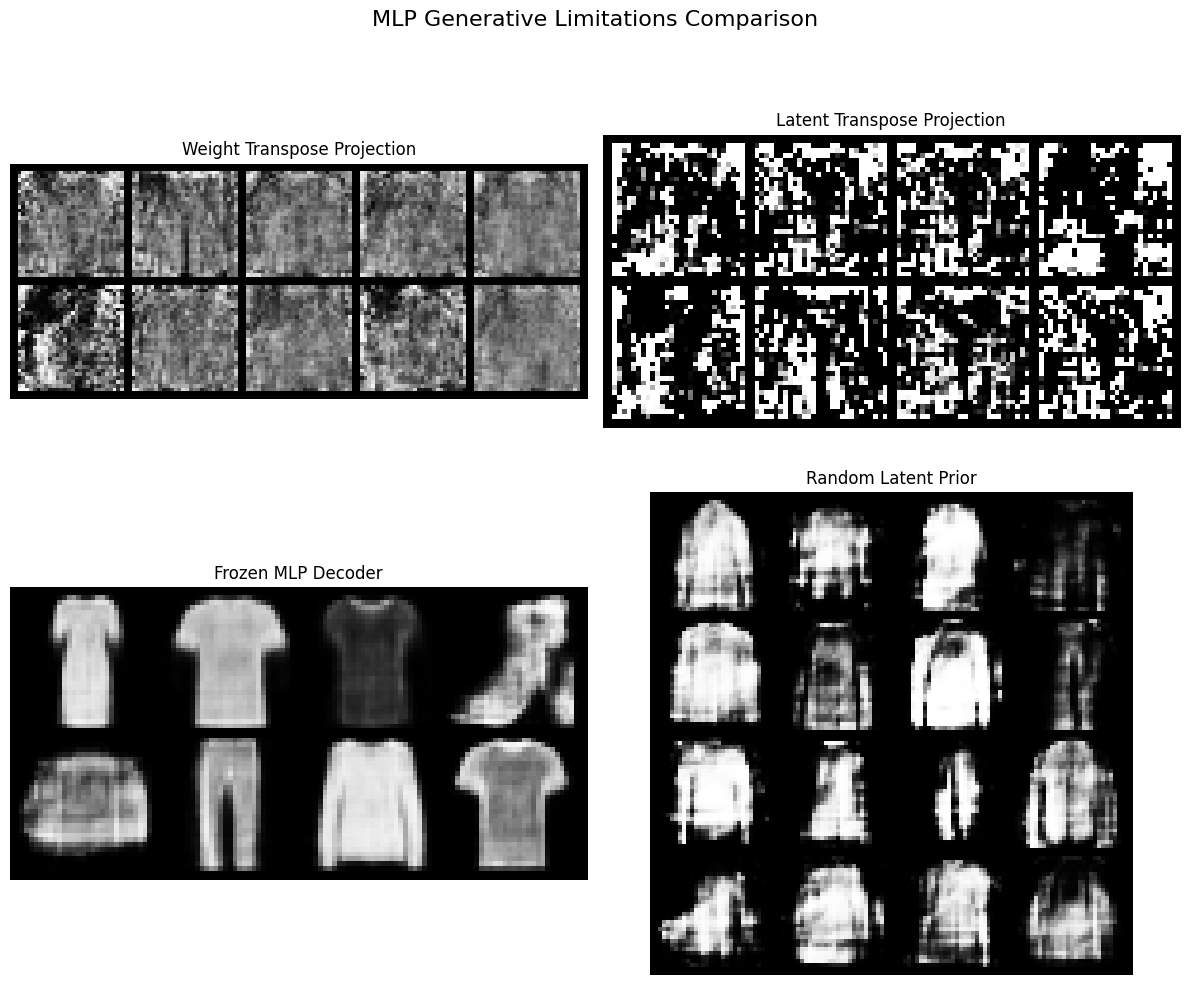

In [43]:
image_dir = "../results/generated_images"

mlp_images = [
    ("Weight Transpose Projection", "mlp_weight_transpose.png"),
    ("Latent Transpose Projection", "mlp_latent_transpose.png"),
    ("Frozen MLP Decoder", "mlp_frozen_decoder.png"),
    ("Random Latent Prior", "mlp_random_prior.png")
]

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (title, filename) in zip(axes.flat, mlp_images):

    img = Image.open(
        os.path.join(image_dir, filename)
    ).convert("RGB")

    ax.imshow(img)
    ax.set_title(title, fontsize=12)
    ax.axis("off")

plt.suptitle(
    "MLP Generative Limitations Comparison",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    "../results/generated_images/mlp_limitation_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [46]:
# Get two real images from test dataset
x1 = test_dataset[0][0].unsqueeze(0).to(device)
x2 = test_dataset[1][0].unsqueeze(0).to(device)

# Interpolation coefficients
steps = 7
alphas_interp = torch.linspace(0, 1, steps, device=device)

def interpolate(z1, z2):
    return torch.cat([
        (1 - a) * z1 + a * z2
        for a in alphas_interp
    ], dim=0)

# Autoencoder interpolation
@torch.no_grad()
def interpolate_ae(model, x1, x2):
    z1 = model.encoder(x1.view(1, -1))
    z2 = model.encoder(x2.view(1, -1))

    z_interp = interpolate(z1, z2)

    return model.decoder(z_interp).view(-1, 1, 28, 28)


# VAE interpolation using mean vectors
@torch.no_grad()
def interpolate_vae(model, x1, x2):
    h1 = model.encoder(x1.view(1, -1))
    h2 = model.encoder(x2.view(1, -1))

    mu1 = model.fc_mu(h1)
    mu2 = model.fc_mu(h2)

    z_interp = interpolate(mu1, mu2)

    return model.decoder(z_interp).view(-1, 1, 28, 28)


# GAN interpolation
@torch.no_grad()
def interpolate_gan(generator, dcgan=False):
    z1 = torch.randn(1, 100, device=device)
    z2 = torch.randn(1, 100, device=device)

    if dcgan:
        z1 = z1.view(1, 100, 1, 1)
        z2 = z2.view(1, 100, 1, 1)

    z_interp = interpolate(z1, z2)

    generated = generator(z_interp)

    if dcgan:
        generated = (generated.clamp(-1, 1) + 1) / 2
    else:
        generated = generated.view(-1, 1, 28, 28)

    return generated


# Generate interpolation results
interpolation_results = {
    "Vanilla AE": interpolate_ae(vanilla_ae, x1, x2),
    "Sparse AE": interpolate_ae(sparse_ae, x1, x2),
    "VAE": interpolate_vae(vae, x1, x2),
    "Vanilla GAN": interpolate_gan(gan_generator),
    "DCGAN": interpolate_gan(dcgan_generator, dcgan=True)
}

print("Interpolation generated successfully!")

for name, images in interpolation_results.items():
    print(name, images.shape)

Interpolation generated successfully!
Vanilla AE torch.Size([7, 1, 28, 28])
Sparse AE torch.Size([7, 1, 28, 28])
VAE torch.Size([7, 1, 28, 28])
Vanilla GAN torch.Size([7, 1, 28, 28])
DCGAN torch.Size([7, 1, 28, 28])


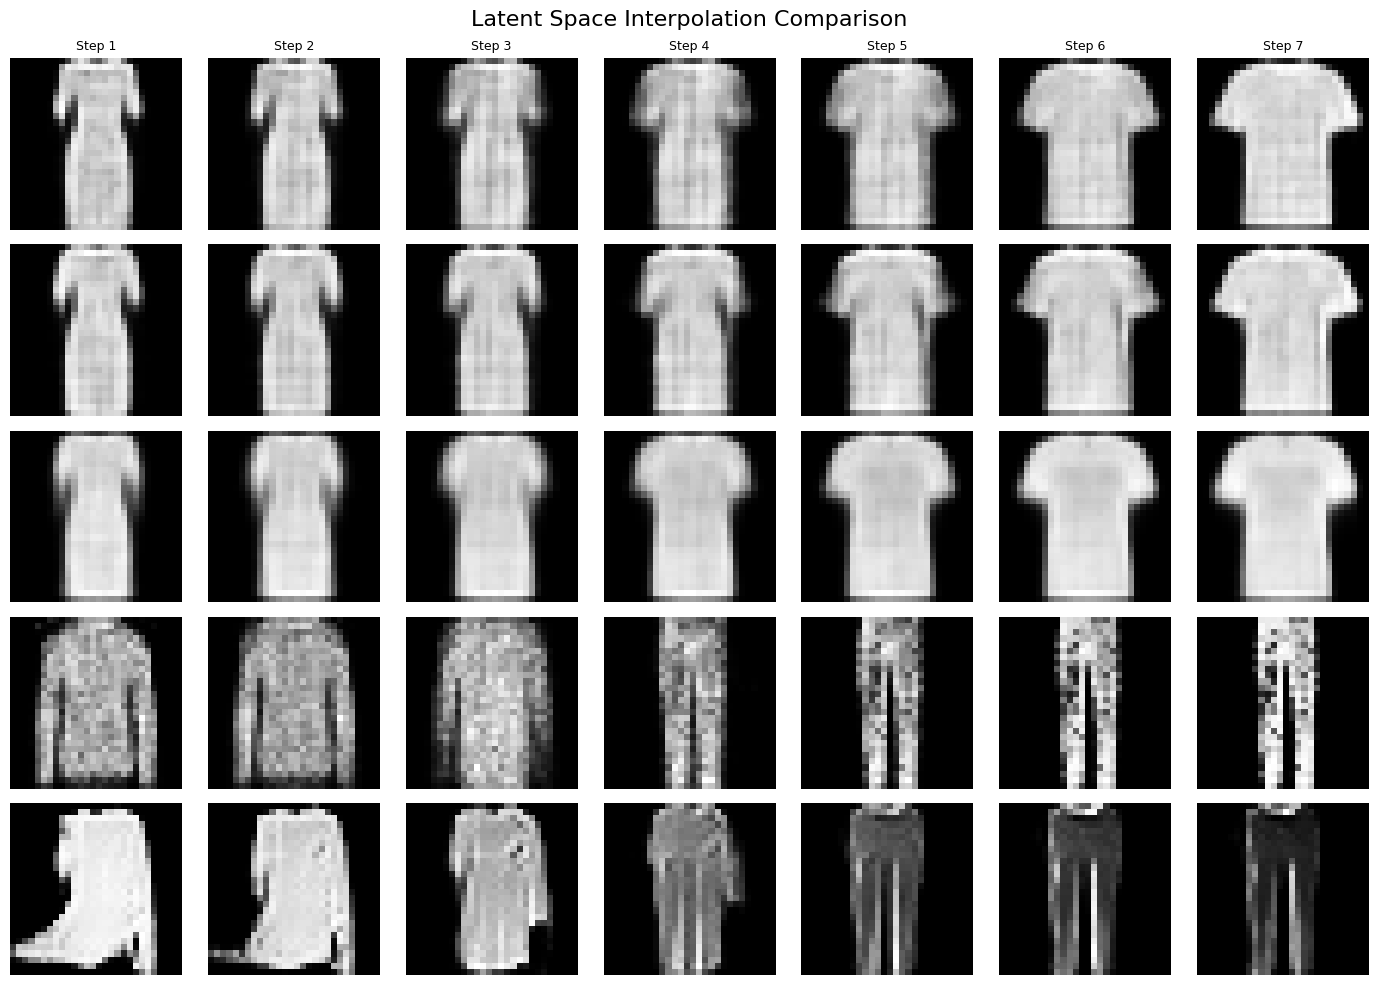

In [47]:
fig, axes = plt.subplots(
    5, 7,
    figsize=(14, 10)
)

for row, (model_name, images) in enumerate(
    interpolation_results.items()
):
    for col in range(7):
        axes[row, col].imshow(
            images[col].squeeze().cpu(),
            cmap="gray"
        )

        axes[row, col].axis("off")

        if row == 0:
            axes[row, col].set_title(
                f"Step {col + 1}",
                fontsize=9
            )

    axes[row, 0].set_ylabel(
        model_name,
        fontsize=10,
        rotation=0,
        labelpad=65
    )

plt.suptitle(
    "Latent Space Interpolation Comparison",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    "../results/generated_images/latent_interpolation_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [48]:
final_results = pd.DataFrame({
    "Model": [
        "Vanilla AE",
        "Sparse AE",
        "VAE",
        "Vanilla GAN",
        "DCGAN",
        "DDPM"
    ],
    "MSE": [
        0.006567,
        0.007825,
        0.017325,
        None,
        None,
        None
    ],
    "PSNR": [
        22.958798,
        22.124467,
        18.295819,
        None,
        None,
        None
    ],
    "SSIM": [
        0.827014,
        0.798745,
        0.640262,
        None,
        None,
        None
    ],
    "FID": [
        None,
        None,
        0.343673,
        0.430921,
        0.010504,
        0.897034
    ],
    "Latency (ms/batch)": [
        0.503617,
        0.464207,
        0.432393,
        0.220013,
        2.229007,
        942.372670
    ]
})

display(final_results)

final_results.to_csv(
    "../results/metrics/final_model_comparison.csv",
    index=False
)

print("Final evaluation table saved!")

,Model,MSE,PSNR,SSIM,FID,Latency (ms/batch)
0,Vanilla AE,0.006567,22.958798,0.827014,NaN,0.503617
1,Sparse AE,0.007825,22.124467,0.798745,NaN,0.464207
2,VAE,0.017325,18.295819,0.640262,0.343673,0.432393
3,Vanilla GAN,NaN,NaN,NaN,0.430921,0.220013
4,DCGAN,NaN,NaN,NaN,0.010504,2.229007
5,DDPM,NaN,NaN,NaN,0.897034,942.372670


Final evaluation table saved!


In [56]:
import pandas as pd

df = pd.read_csv("../results/metrics/final_model_comparison.csv")
display(df)

,Model,MSE,PSNR,SSIM,FID,Latency (ms/batch)
0,Vanilla AE,0.006567,22.958798,0.827014,NaN,0.503617
1,Sparse AE,0.007825,22.124467,0.798745,NaN,0.464207
2,VAE,0.017325,18.295819,0.640262,0.343673,0.432393
3,Vanilla GAN,NaN,NaN,NaN,0.430921,0.220013
4,DCGAN,NaN,NaN,NaN,0.010504,2.229007
5,DDPM,NaN,NaN,NaN,0.897034,942.372670


In [57]:
dcgan_samples = torch.load(
    "../results/generated_images/fid_samples/dcgan_samples.pt",
    map_location="cpu",
    weights_only=True
)

print("Shape:", dcgan_samples.shape)
print("Minimum:", dcgan_samples.min().item())
print("Maximum:", dcgan_samples.max().item())
print("Mean:", dcgan_samples.mean().item())
print("Std:", dcgan_samples.std().item())

Shape: torch.Size([2000, 1, 28, 28])
Minimum: 0.0
Maximum: 0.9999594688415527
Mean: 0.285055547952652
Std: 0.3535532057285309


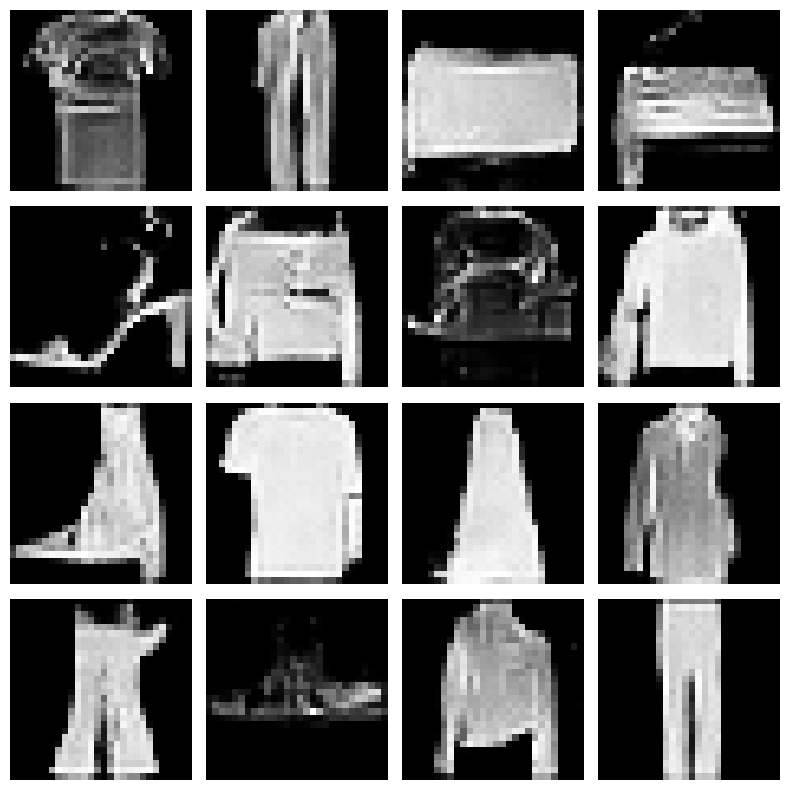

In [58]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(4, 4, figsize=(8, 8))

for i, ax in enumerate(axes.flat):
    ax.imshow(dcgan_samples[i].squeeze(), cmap="gray")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [59]:
real_samples = torch.load(
    "../results/generated_images/fid_samples/real_samples.pt",
    map_location="cpu",
    weights_only=True
)

print("Shape:", real_samples.shape)
print("Minimum:", real_samples.min().item())
print("Maximum:", real_samples.max().item())
print("Mean:", real_samples.mean().item())
print("Std:", real_samples.std().item())

Shape: torch.Size([2000, 1, 28, 28])
Minimum: 0.0
Maximum: 1.0
Mean: 0.2945605218410492
Std: 0.35633379220962524


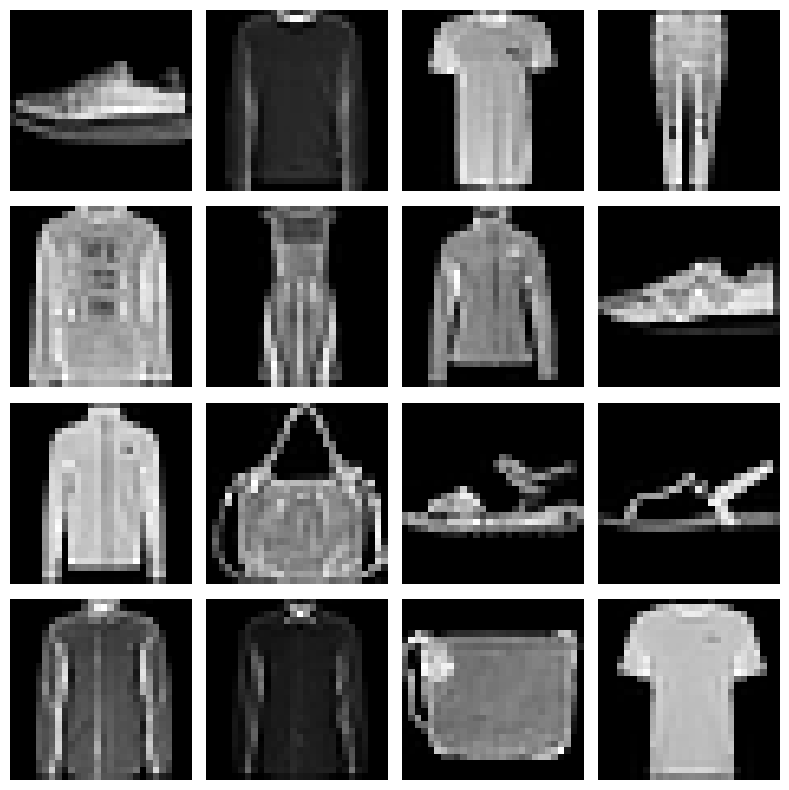

In [60]:
fig, axes = plt.subplots(4, 4, figsize=(8, 8))

for i, ax in enumerate(axes.flat):
    ax.imshow(real_samples[i].squeeze(), cmap="gray")
    ax.axis("off")

plt.tight_layout()
plt.show()